# Vision, support surface, and age in quiet-stance postural sway

**Víctor Andrés Gómez López**

Private analysis of the Human Balance Evaluation Database, version 1.0.0. The raw recordings are downloaded locally and are not part of this project.

## Question

In adults who completed every quiet-stance condition, how much does resultant center-of-pressure mean velocity change when the eyes are closed and when a firm surface is replaced by foam? Is that eyes-closed change larger on foam than on the firm surface?

The secondary question uses the age groups supplied with the database: younger than 60 years, and 60 years or older.

The primary estimand is the interaction for resultant mean velocity, in cm/s. Each participant contributes one number. This notebook does not estimate a treatment effect, a diagnostic cutoff, or a training recommendation.

## License

The original writing, code, tests, and figure design in this project are under CC BY 4.0 (`LICENSE`). That license does not relicense the database.

The PhysioNet record for version 1.0.0 serves the Open Data Commons Attribution License v1.0. The 2016 PeerJ article says the PhysioNet copy used ODC-PDDL. This project follows the license page served with the files. See `DATA_LICENSE.md`.

Cite Santos DA, Duarte M. A public data set of human balance evaluations. PeerJ. 2016;4:e2648. https://doi.org/10.7717/peerj.2648

Cite Santos DA, Duarte M. Human Balance Evaluation Database (version 1.0.0). PhysioNet. 2016. https://doi.org/10.13026/C2WW2W


## How the numbers are built

Recordings are 60 s at 100 Hz and were already low-pass filtered at 10 Hz. Resultant mean velocity is COP path length divided by 59.99 s. The 95% area is the prediction ellipse of the COP cloud, not a confidence ellipse of the mean.

Participants with all four conditions are kept. Three repetitions are averaged inside each person and condition. Intervals are percentile bootstrap intervals over people (10,000 draws, seed 2648). Sign-flip and label-permutation p values use the same unit. A trial-level regression is shown only with subject-clustered standard errors.

Illness, medication, disability descriptions, skin color, and nationality are not loaded into the analysis tables.


In [1]:
from pathlib import Path
import sys

ROOT = Path.cwd()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

from hbedb_sway.pipeline import run_analysis

result = run_analysis(ROOT / "data" / "raw", ROOT / "outputs", results_path=ROOT / "RESULTS.md")
print(
    f"Analytic participants: {result.quality['n_subjects_analytic']}. "
    f"Trials excluded by quality control: {result.quality['n_trials_excluded']}."
)


Read 250 of 1930 trials


Read 500 of 1930 trials


Read 750 of 1930 trials


Read 1000 of 1930 trials


Read 1250 of 1930 trials


Read 1500 of 1930 trials


Read 1750 of 1930 trials


Read 1930 of 1930 trials


Analytic participants: 158. Trials excluded by quality control: 0.


## Sample

The sample size in every interval is the number of participants. The age histogram shows why a linear age slope mostly restates two clusters. The vertical line is the source cutoff at 60 years.


,group,group_label,n,n_female,n_male,age_min,age_median,age_max,height_cm_mean,weight_kg_mean,foot_len_cm_mean,n_disability,n_missing_foot
0,All,All analytic participants,158,114,44,18.333333,39.833333,85.833333,162.465190,62.178797,22.993269,12,2
1,Young,Younger than 60 years,86,56,30,18.333333,25.458333,59.000000,166.741860,61.508140,23.247024,3,2
2,Old,60 years or older,72,58,14,60.500000,71.791667,85.833333,157.356944,62.979861,22.697222,9,0


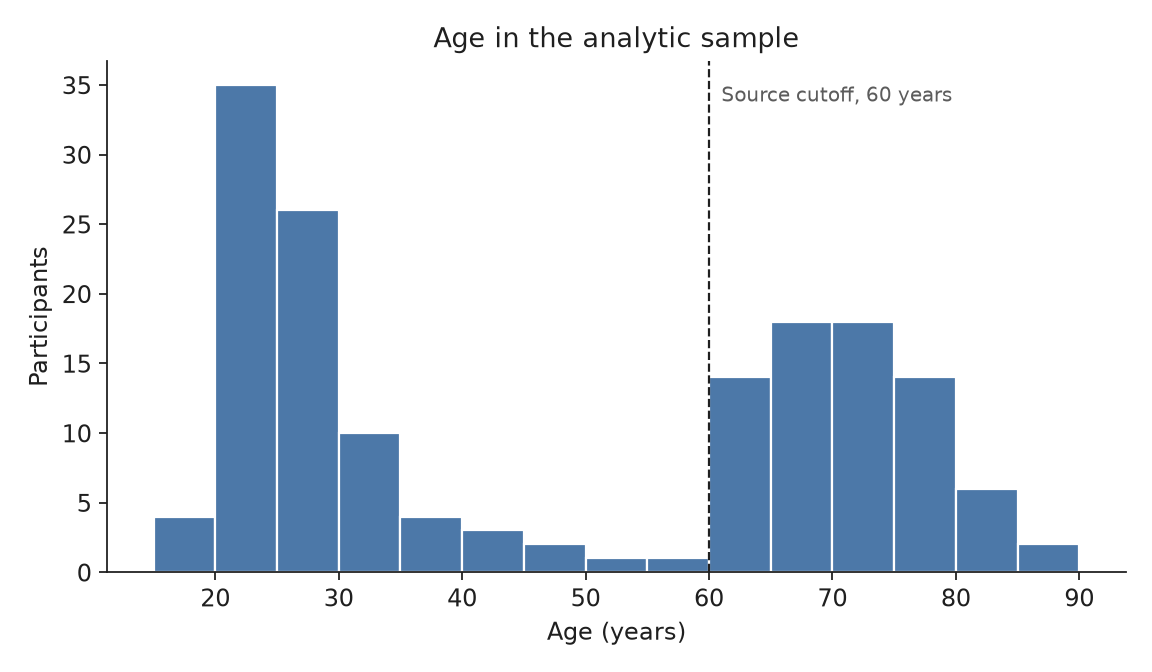

In [2]:
from IPython.display import Image, display

display(result.sample)
display(Image(filename=str(ROOT / "outputs" / "figures" / "age_distribution.png")))


## Primary contrasts

Positive values mean more sway in the more demanding condition. The interaction is the extra eyes-closed effect on foam.

Caption. Participant-level mean resultant velocity by vision and surface, and the within-subject contrasts. Error bars and horizontal lines are 95% bootstrap confidence intervals across participants. Each person counts once. The analytic sample is the 158 adults with all four conditions.


,contrast_label,n_subjects,mean,ci_low,ci_high,median,n_positive,perm_p
0,"Eyes closed minus eyes open, firm surface",158,0.101171,0.060984,0.144623,0.072436,109,0.00005
1,"Eyes closed minus eyes open, foam surface",158,0.752977,0.659351,0.854969,0.626342,146,0.00005
2,"Foam minus firm, eyes open",158,1.961106,1.842839,2.084177,1.808915,158,0.00005
3,"Foam minus firm, eyes closed",158,2.612912,2.471340,2.762600,2.483393,158,0.00005
4,Interaction: extra eyes-closed effect on foam,158,0.651806,0.559176,0.745088,0.600949,145,0.00005


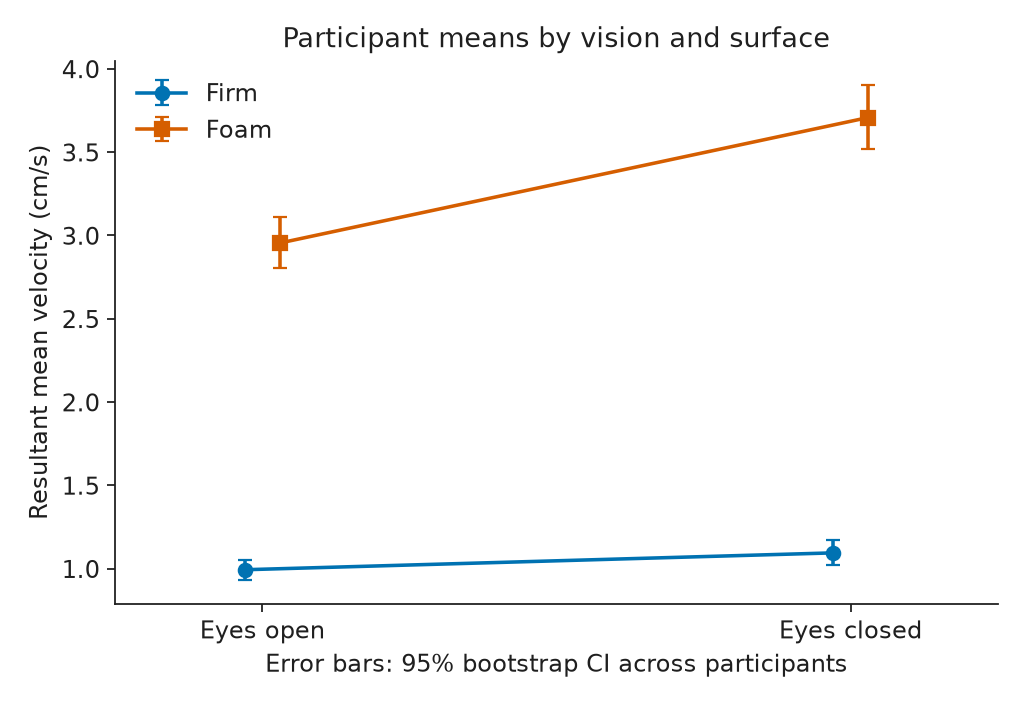

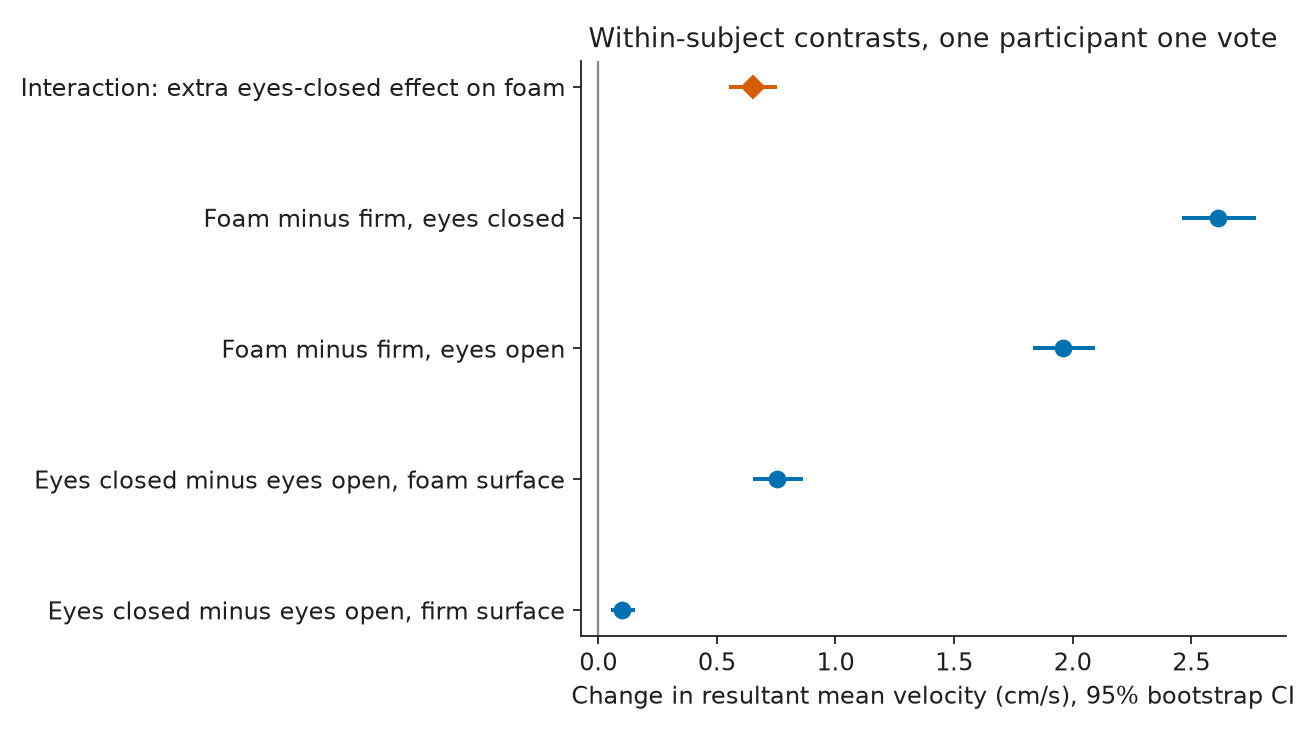

In [3]:
velocity = result.contrast_summary[result.contrast_summary["outcome"].eq("mv_cm_s")]
columns = [
    "contrast_label",
    "n_subjects",
    "mean",
    "ci_low",
    "ci_high",
    "median",
    "n_positive",
    "perm_p",
]
display(velocity[columns])
display(Image(filename=str(ROOT / "outputs" / "figures" / "condition_means.png")))
display(Image(filename=str(ROOT / "outputs" / "figures" / "forest_mean_velocity.png")))


## Age

Older minus younger, in cm/s. The foam effect is larger in the older group. The interaction interval includes zero.

Caption. The same participant-level means, split by the source age groups, and the older-minus-younger differences. Error bars are 95% bootstrap confidence intervals. The scatter shows one point per participant. The line is a least-squares fit, not a claim of a smooth age effect. Few adults fall between 40 and 60 years.


,contrast_label,n_young,n_old,diff_old_minus_young,ci_low,ci_high,perm_p
0,"Eyes closed minus eyes open, firm surface",86,72,0.029024,-0.055379,0.122541,0.510474
1,"Eyes closed minus eyes open, foam surface",86,72,-0.025933,-0.226153,0.182074,0.802260
2,"Foam minus firm, eyes open",86,72,0.996334,0.807356,1.182170,0.000050
3,"Foam minus firm, eyes closed",86,72,0.941377,0.680774,1.205208,0.000050
4,Interaction: extra eyes-closed effect on foam,86,72,-0.054957,-0.254235,0.141976,0.571721


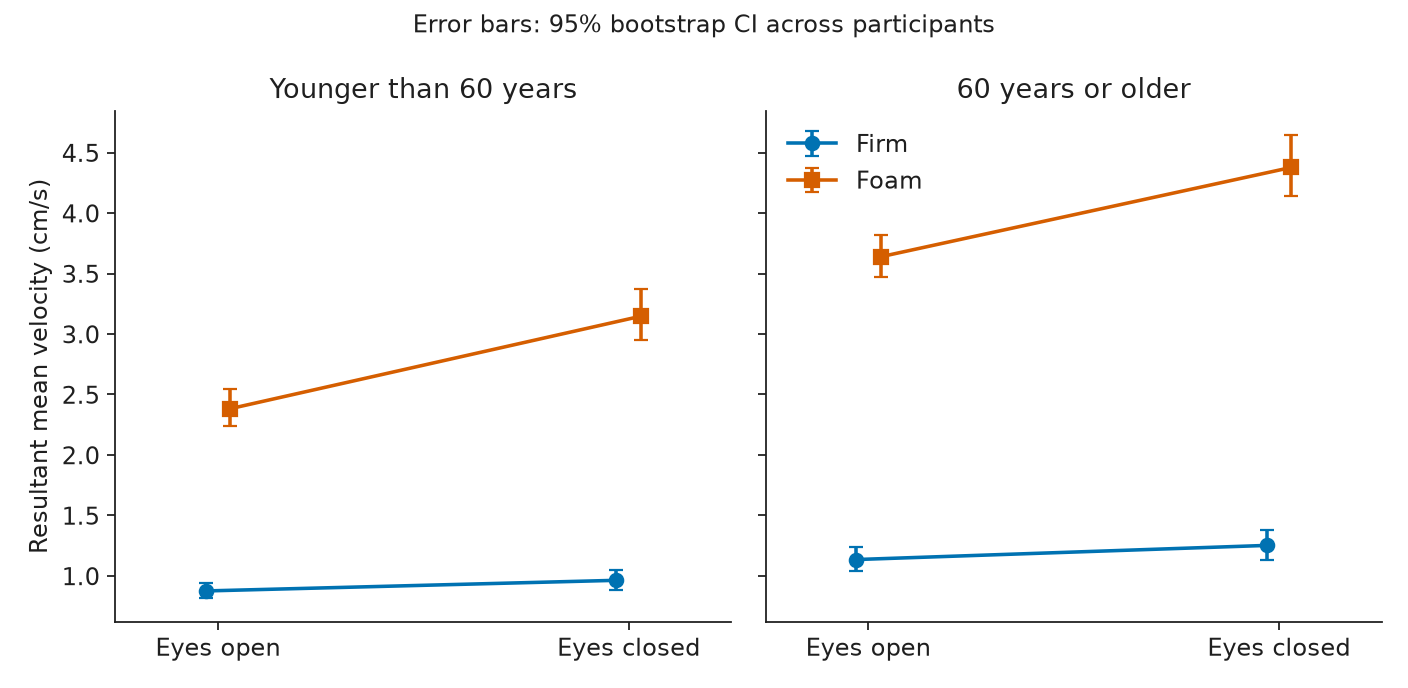

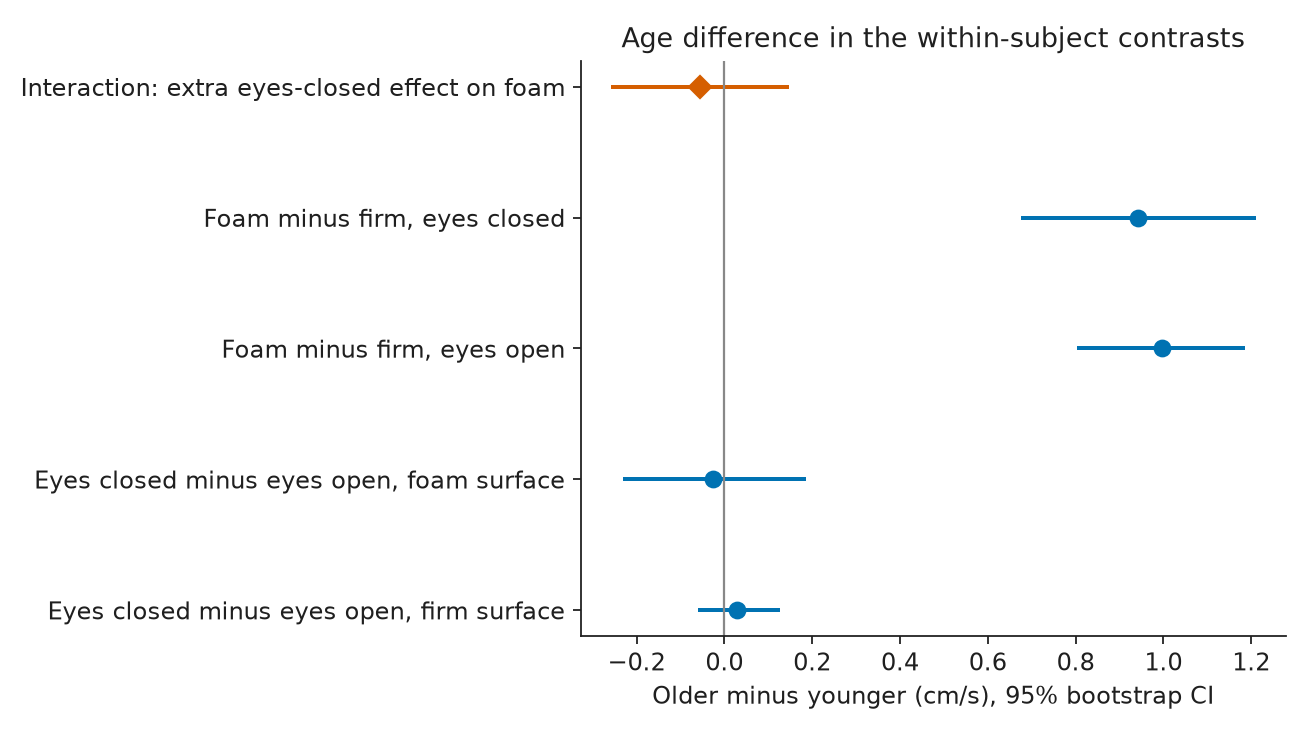

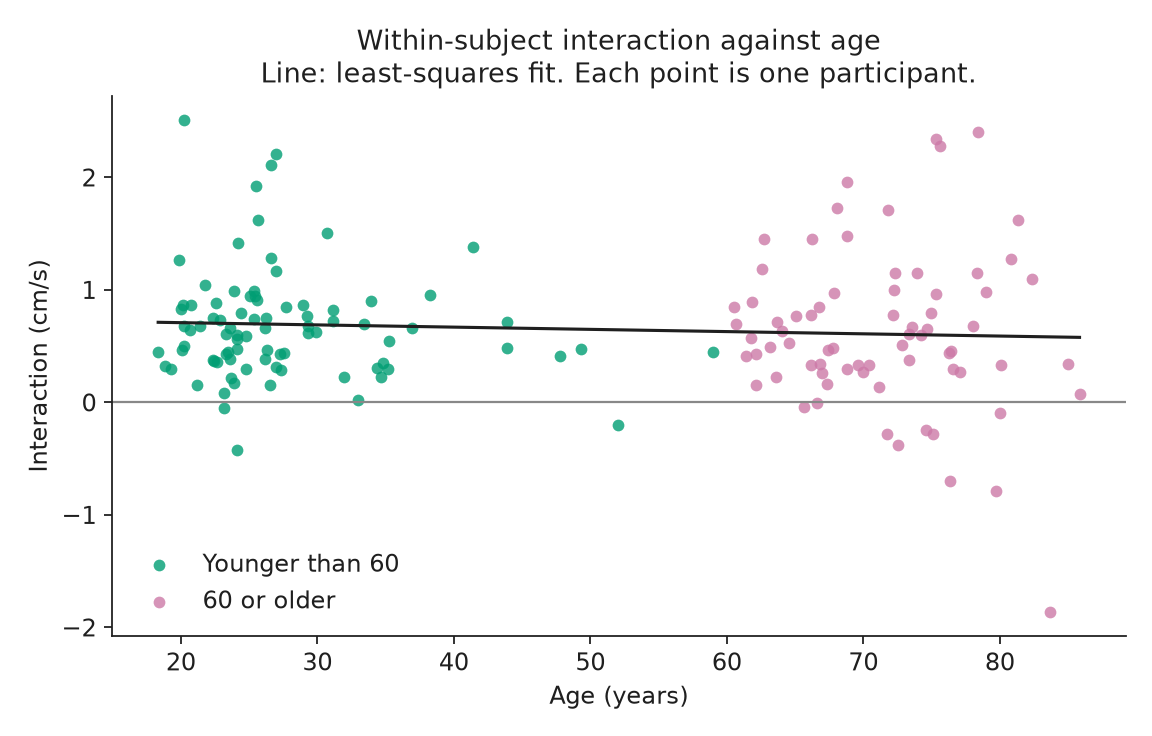

In [4]:
age = result.age_summary[result.age_summary["outcome"].eq("mv_cm_s")]
display(age[["contrast_label", "n_young", "n_old", "diff_old_minus_young", "ci_low", "ci_high", "perm_p"]])
display(Image(filename=str(ROOT / "outputs" / "figures" / "condition_means_by_age.png")))
display(Image(filename=str(ROOT / "outputs" / "figures" / "forest_age_differences.png")))
display(Image(filename=str(ROOT / "outputs" / "figures" / "interaction_vs_age.png")))


## Signal check and one illustration

Stored COP is compared with the source moment formulas. The stabilogram is one participant near the median firm, eyes-open velocity. Panels share a scale and show demeaned COP. No identifier is shown. It is an illustration of the signal, not a summary of the 158 participants.

Caption. Quality screens for vertical force and the largest sample-to-sample step, then one four-panel stabilogram, then the anteroposterior and mediolateral contrasts. Those axis intervals are also 95% bootstrap confidence intervals across participants.


Largest COP reconstruction error among included trials, cm: 2.612e-07
Vertical force / body weight, min to max: 0.950 to 1.037


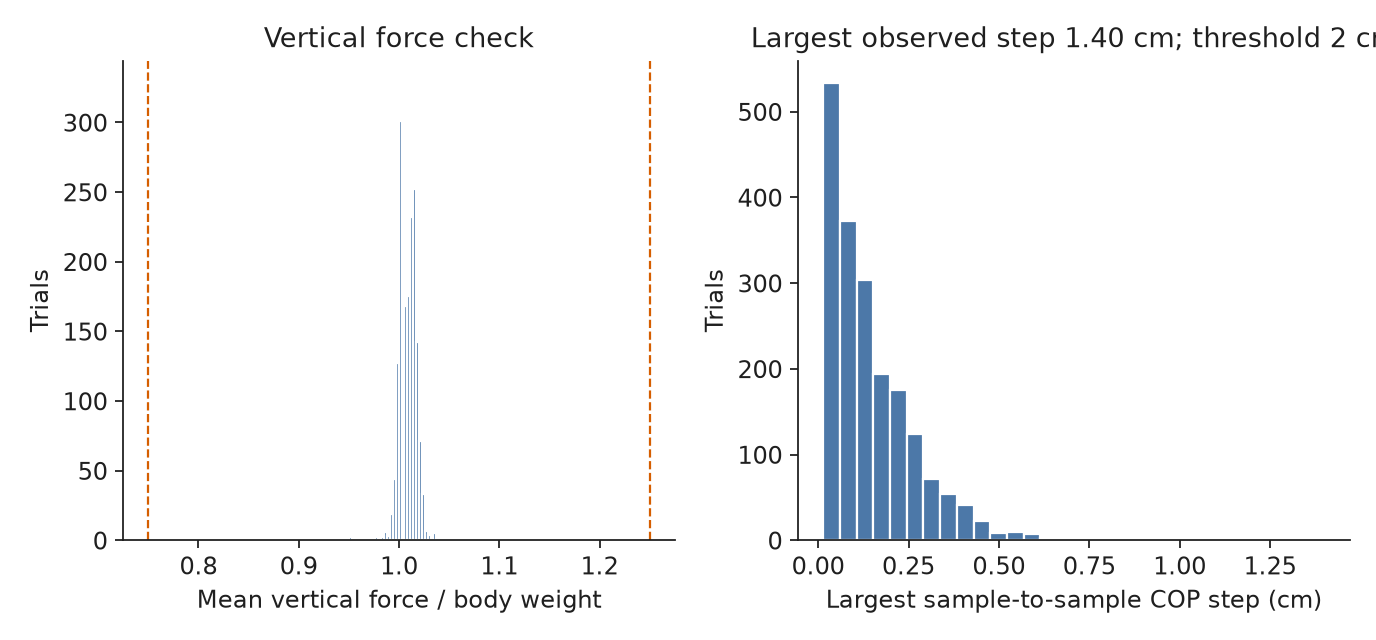

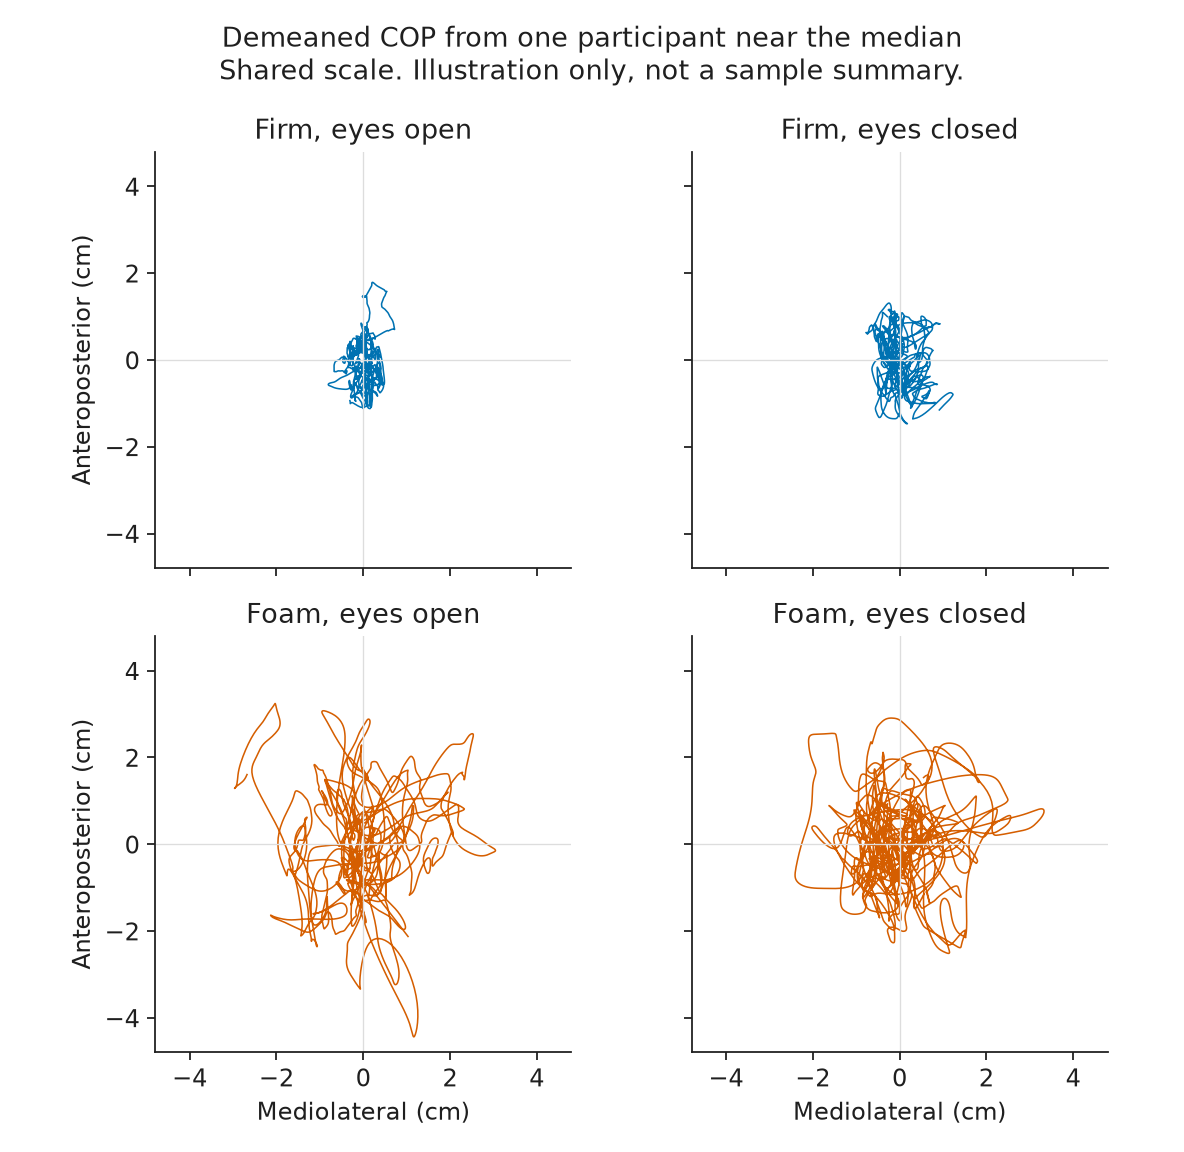

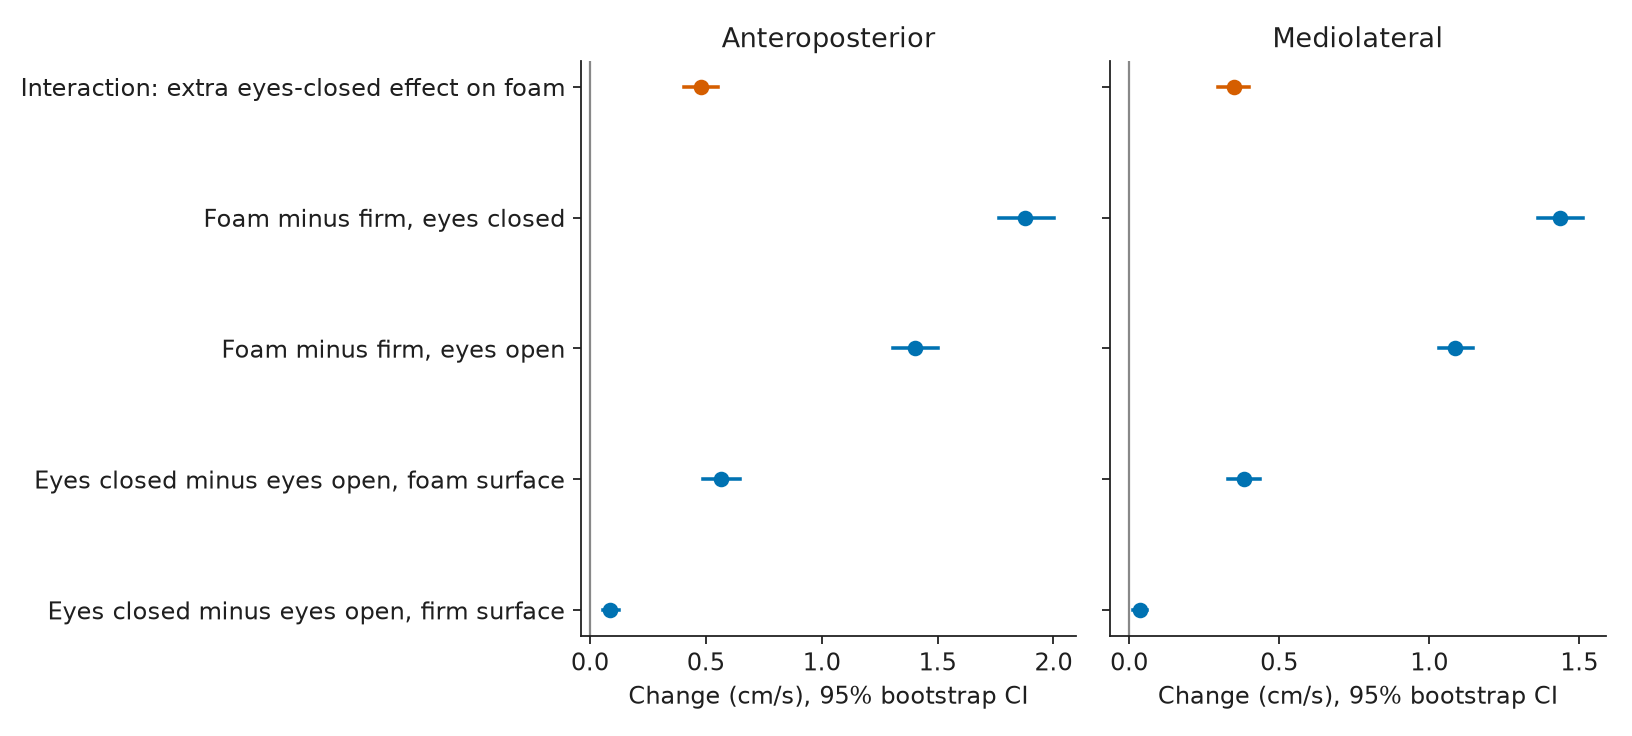

In [5]:
print(
    "Largest COP reconstruction error among included trials, cm:",
    f"{result.quality['cop_recon_max_cm']:.3e}",
)
print(
    "Vertical force / body weight, min to max:",
    f"{result.quality['fz_ratio_min']:.3f}",
    "to",
    f"{result.quality['fz_ratio_max']:.3f}",
)
display(Image(filename=str(ROOT / "outputs" / "figures" / "quality_checks.png")))
display(Image(filename=str(ROOT / "outputs" / "figures" / "example_stabilogram.png")))
display(Image(filename=str(ROOT / "outputs" / "figures" / "forest_axes.png")))


## What not to conclude

These are quiet-stance COP changes in a convenience sample, mostly women, recorded in one laboratory. Five participants did not finish the harder conditions, and those trials were not imputed. The estimates are not a treatment effect, not a diagnostic tool, and not a training recommendation.

The numerical write-up, the license caveat, and the full limitation list are in `RESULTS.md`, `DATA_LICENSE.md`, and `LICENSE`.
